In [131]:
import pandas as pd
import numpy as np
import datetime
import seaborn as sns
import matplotlib.pyplot as plt

TopFly Knight

In [132]:
raw_data=pd.read_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zonar\knight.csv',sep=',')
raw_data.info()
print(raw_data.iloc[(raw_data.shape[0]-1),3],' -> ',raw_data.iloc[0,3])

<class 'pandas.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 29 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Row Id                     53 non-null     int64  
 1   Sequence #                 53 non-null     int64  
 2   Account Id                 53 non-null     int64  
 3   Server Time                53 non-null     str    
 4   Unit Time                  53 non-null     str    
 5   Latitude                   53 non-null     float64
 6   Longitude                  53 non-null     float64
 7   Driver Name                34 non-null     str    
 8   Event Name                 53 non-null     str    
 9   Raw Event                  53 non-null     str    
 10  GPS Speed                  53 non-null     float64
 11  ECU Speed                  0 non-null      float64
 12  Address                    53 non-null     str    
 13  Landmark ID                0 non-null      float64
 14  Satelli

In [133]:
aux=pd.DataFrame()
aux=raw_data
aux['Headers']='NaN'

for i in range(0,aux.shape[0]):
    aux.iloc[i,29]=aux.iloc[i,28][0:8]

aux['Headers'].value_counts()

Headers
27270200    31
27270400    22
Name: count, dtype: int64

Odometer

In [134]:
unit_02=aux[aux['Raw Data'].str.contains('27270200')]
unit_04=aux[aux['Raw Data'].str.contains('27270400')]
unit_aux=pd.concat([unit_02,unit_04])
unit_aux['Odometer in meters']=0.0
odometer=[]
date=[]
raw=[]

for i in range(0,unit_aux.shape[0]):
    odometer.append(int(unit_aux.iloc[i,28][96:104],16))
    date.append(unit_aux.iloc[i,28][34:46])
    raw.append(unit_aux.iloc[i,28])

unit_aux['Odometer in meters']=odometer
unit_aux['Date']=date
unit_aux['Raw data']=raw

unit=unit_aux.sort_values('Date',ascending=True)

unit.info()

<class 'pandas.DataFrame'>
Index: 53 entries, 52 to 0
Data columns (total 33 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Row Id                     53 non-null     int64  
 1   Sequence #                 53 non-null     int64  
 2   Account Id                 53 non-null     int64  
 3   Server Time                53 non-null     str    
 4   Unit Time                  53 non-null     str    
 5   Latitude                   53 non-null     float64
 6   Longitude                  53 non-null     float64
 7   Driver Name                34 non-null     str    
 8   Event Name                 53 non-null     str    
 9   Raw Event                  53 non-null     str    
 10  GPS Speed                  53 non-null     float64
 11  ECU Speed                  0 non-null      float64
 12  Address                    53 non-null     str    
 13  Landmark ID                0 non-null      float64
 14  Satellites  

261014130747 -> 0 -> 1428.0 -> 272702004900620869487062952667ce002610141307472d282145a03494c29dcd93400000000000181080005214ff37000005944e00040258000038400000000010f280000000ff80
261014131733 -> 1 -> 1428.0 -> 2727020049006308694870629526674d002610141317332d282145a03494c29dcd93400000000080180980405314ff37000005944e04f40258000038400000000010f280000000ffd5
261014153439 -> 2 -> 1509.0 -> 2727040049006008694870629526674e162610141534399c242345120f94c29f859640000000ac8008008090501aff37000005e5ce06440258000038400000000010f280000000ffd5
261014153446 -> 3 -> 1510.0 -> 272702004900640869487062952667530026101415344675112345280f94c2577d9640006000c38028008090501aff37000005e64006440258000038400000000010f280000000ffd5
261014154530 -> 4 -> 1521.0 -> 272702004900650869487062952667cd0026101415453098a02145631494c261889640000001080008018090501aff37000005f1ba00040258000038400000000010f280000000ff80
261014155403 -> 5 -> 1522.0 -> 2727040049006108694870629526674e1726101415540314402145681594c2af8a9640000000048

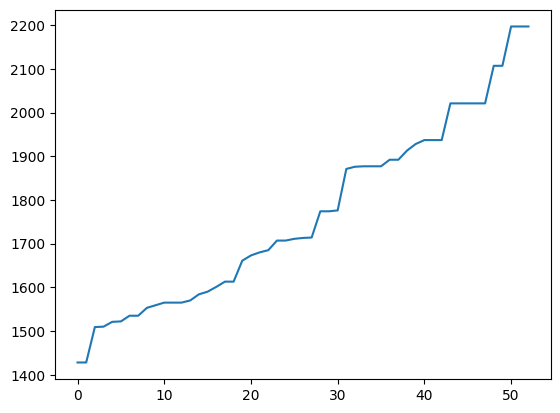

In [135]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,30]))
    x_axis.append(i)
    date.append(unit.iloc[i,31])
    raw_data_.append(unit.iloc[i,32])

#print("Delta odometer: ",y_axis[170]-y_axis[133],'meters')

for i in range(0,len(odometer)):
    print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

#print(odometer[len(odometer)-1]-odometer[0])
plt.plot(x_axis,y_axis)

Speed

In [136]:
speed=[]

for i in range(0,unit.shape[0]):
    speed.append(int(unit.iloc[i,32][70:74]))
    date.append(unit.iloc[i,28][34:46])
    raw.append(unit.iloc[i,28])
    #print(unit.iloc[i,32][70:74],int(unit.iloc[i,32][70:74]))

unit['Speed']=speed

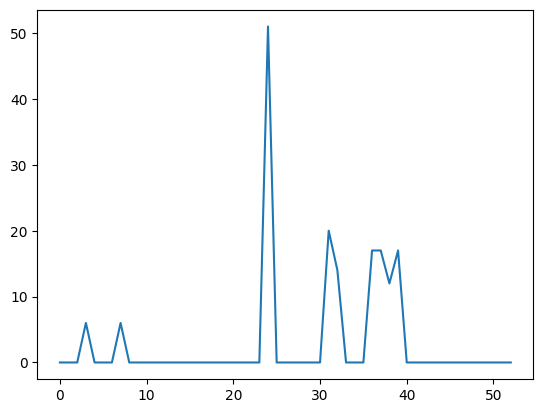

In [137]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append((float(unit.iloc[i,33]))/10)
    x_axis.append(i)
    date.append(unit.iloc[i,31])
    raw_data_.append(unit.iloc[i,32])
    #print(raw_data_[i])

for i in range(0,len(speed)):
    if (y_axis[i]>55):
        print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

plt.plot(x_axis,y_axis)

Battery

In [138]:
voltage=[]

for i in range(0,unit.shape[0]):
    voltage.append(int(unit.iloc[i,32][75:77],16))
    date.append(unit.iloc[i,28][34:46])
    raw.append(unit.iloc[i,28])
    #print(unit.iloc[i,32][70:74],int(unit.iloc[i,32][70:74]))

unit['Voltage']=voltage

unit.info()

<class 'pandas.DataFrame'>
Index: 53 entries, 52 to 0
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Row Id                     53 non-null     int64  
 1   Sequence #                 53 non-null     int64  
 2   Account Id                 53 non-null     int64  
 3   Server Time                53 non-null     str    
 4   Unit Time                  53 non-null     str    
 5   Latitude                   53 non-null     float64
 6   Longitude                  53 non-null     float64
 7   Driver Name                34 non-null     str    
 8   Event Name                 53 non-null     str    
 9   Raw Event                  53 non-null     str    
 10  GPS Speed                  53 non-null     float64
 11  ECU Speed                  0 non-null      float64
 12  Address                    53 non-null     str    
 13  Landmark ID                0 non-null      float64
 14  Satellites  

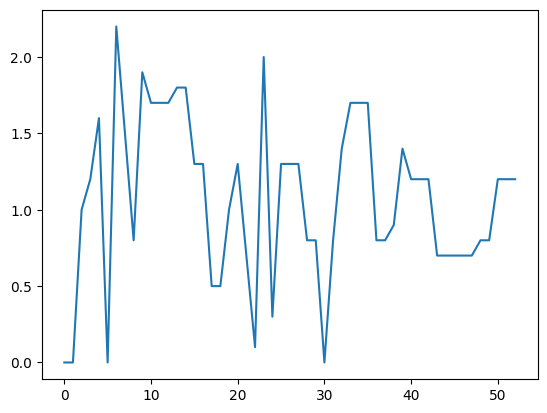

In [139]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,34])/10)
    x_axis.append(i)
    date.append(unit.iloc[i,31])
    raw_data_.append(unit.iloc[i,32])
    #print(raw_data_[i])

for i in range(0,len(voltage)):
    if (y_axis[i]>55):
        print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

plt.plot(x_axis,y_axis)

Panic

In [140]:
for i in range(0,unit.shape[0]):
    #print(unit.iloc[i,32][32:34])
    if (unit.iloc[i,32][32:34]=='03'):
        print('Panic',unit.iloc[i,31])